# GROUP 6 DEMO

### Importing all necessary modules

In [71]:
import pandas as pd
from sklearn.model_selection import train_test_split,KFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import seaborn as sns




### Reading the csv file

In [74]:
df = pd.read_csv("diabetes.csv")
df

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1


### Data Preprocessing

In [77]:
print(df.isnull().sum())

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


In [79]:
x = df.drop(columns = 'Outcome')
x 

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,6,148,72,35,0,33.6,0.627,50
1,1,85,66,29,0,26.6,0.351,31
2,8,183,64,0,0,23.3,0.672,32
3,1,89,66,23,94,28.1,0.167,21
4,0,137,40,35,168,43.1,2.288,33
...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63
764,2,122,70,27,0,36.8,0.340,27
765,5,121,72,23,112,26.2,0.245,30
766,1,126,60,0,0,30.1,0.349,47


In [81]:
y = df['Outcome']
y

0      1
1      0
2      1
3      0
4      1
      ..
763    0
764    0
765    0
766    1
767    0
Name: Outcome, Length: 768, dtype: int64

In [83]:
x_train,x_test, y_train,y_test =train_test_split(x,y, test_size = 0.3, random_state = 21)

In [85]:
x_train

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
668,6,98,58,33,190,34.0,0.430,43
623,0,94,70,27,115,43.5,0.347,21
537,0,57,60,0,0,21.7,0.735,67
27,1,97,66,15,140,23.2,0.487,22
613,6,105,80,28,0,32.5,0.878,26
...,...,...,...,...,...,...,...,...
419,3,129,64,29,115,26.4,0.219,28
120,0,162,76,56,100,53.2,0.759,25
368,3,81,86,16,66,27.5,0.306,22
48,7,103,66,32,0,39.1,0.344,31


In [87]:
x_test

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
93,4,134,72,0,0,23.8,0.277,60
42,7,106,92,18,0,22.7,0.235,48
194,8,85,55,20,0,24.4,0.136,42
130,4,173,70,14,168,29.7,0.361,33
676,9,156,86,0,0,24.8,0.230,53
...,...,...,...,...,...,...,...,...
320,4,129,60,12,231,27.5,0.527,31
113,4,76,62,0,0,34.0,0.391,25
242,3,139,54,0,0,25.6,0.402,22
57,0,100,88,60,110,46.8,0.962,31


### Scaling the variables

In [90]:
#Standardization of features in the dataset
#This process is essential when features are on different scales, as it ensures that each feature contributes equally to the model.
scaler = StandardScaler()

In [92]:
x_train_scaled = scaler.fit_transform(x_train)

In [94]:
x_test_scaled = scaler.transform(x_test)

In [96]:
x_train_scaled

array([[ 0.63184964, -0.73629854, -0.5688989 , ...,  0.22448577,
        -0.10941403,  0.84258826],
       [-1.15395698, -0.85852183,  0.03395992, ...,  1.42153201,
        -0.35988619, -1.07761577],
       [-1.15395698, -1.98908719, -0.46842243, ..., -1.32537411,
         0.81099569,  2.93735629],
       ...,
       [-0.26105367, -1.25574749,  0.83777169, ..., -0.59454587,
        -0.48361339, -0.99033377],
       [ 0.92948408, -0.58351944, -0.16699302, ...,  0.86711059,
        -0.3689394 , -0.20479576],
       [ 0.33421521,  1.21927397,  1.74205992, ...,  0.69070378,
        -0.9513626 ,  1.62812627]])

In [98]:
x_test_scaled 

array([[ 0.03658077,  0.363711  ,  0.13443639, ..., -1.06076389,
        -0.57112776,  2.32638228],
       [ 0.92948408, -0.49185198,  1.1392011 , ..., -1.19936924,
        -0.69787271,  1.27899826],
       [ 1.22711852, -1.13352421, -0.7196136 , ..., -0.98516097,
        -0.99662865,  0.75530626],
       ...,
       [-0.26105367,  0.5164901 , -0.76985184, ..., -0.83395512,
        -0.19391066, -0.99033377],
       [-1.15395698, -0.6751869 ,  0.93824816, ...,  1.83734808,
         1.49602194, -0.20479576],
       [-1.15395698, -0.82796601,  0.78753345, ...,  0.65290232,
        -0.66165986, -0.81576977]])

### Train the module

In [101]:
log_reg = LogisticRegression(random_state = 0,max_iter=1000)
log_reg.fit(x_train_scaled,y_train)

LogisticRegression(max_iter=1000, random_state=0)

In [103]:
log_reg.predict(x_train_scaled)

array([0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0,
       1, 0, 0, 1, 0, 0, 1, 1, 0, 0, 1, 1, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0,
       0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0,
       0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 1,
       0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1,
       0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 1, 1,
       1, 1, 0, 1, 1, 0, 1, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0,
       1, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1,
       0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0,
       0, 0, 1, 0, 1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 1, 1, 0, 0, 0, 1, 0, 0,
       0, 1, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1,
       0, 0, 0, 1, 1, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0,

### Model Evaluation

In [106]:
log_reg.score(x_train_scaled,y_train)

0.7988826815642458

In [108]:
log_reg.score(x_test_scaled, y_test)

0.7359307359307359

In [110]:
log_reg_1 = LogisticRegression(random_state = 0,
                             C = 1, 
                             fit_intercept = True, 
                            ).fit(x_train_scaled,y_train)

In [112]:
log_reg_1.score(x_train_scaled,y_train)

0.7988826815642458

In [114]:
log_reg_1.score(x_test_scaled, y_test)

0.7359307359307359

In [116]:
# Perform cross-validation
kf = KFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(log_reg, x, y, cv=kf, scoring='accuracy')

In [118]:
# Print the accuracy for each fold
print(f'Cross-validation scores: {cv_scores}')

Cross-validation scores: [0.74675325 0.78571429 0.74675325 0.81045752 0.75163399]


In [120]:
# Compute the average accuracy
mean_cv_score = cv_scores.mean()
print(f'Average cross-validation score: {mean_cv_score}')

Average cross-validation score: 0.7682624564977505


In [122]:
model = LogisticRegression(max_iter=1000)
model.fit(x_train_scaled, y_train)

LogisticRegression(max_iter=1000)

In [124]:
y_pred = model.predict(x_test_scaled)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.73      0.91      0.81       144
           1       0.75      0.45      0.56        87

    accuracy                           0.74       231
   macro avg       0.74      0.68      0.69       231
weighted avg       0.74      0.74      0.72       231



In [126]:
# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred)
print('Confusion Matrix:')
print(cm)

Confusion Matrix:
[[131  13]
 [ 48  39]]


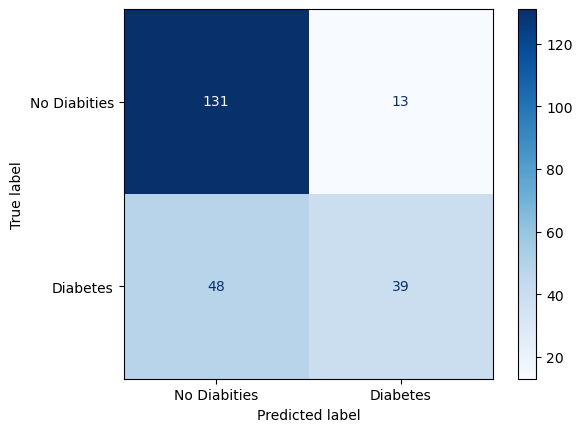

In [128]:
# Plot confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Diabities', 'Diabetes'])
disp.plot(cmap=plt.cm.Blues)
plt.show()

In [130]:
coefficients = model.coef_[0]
feature_names = x.columns

In [132]:
coef_df = pd.DataFrame({'Feature': feature_names, 'Coefficient': coefficients})

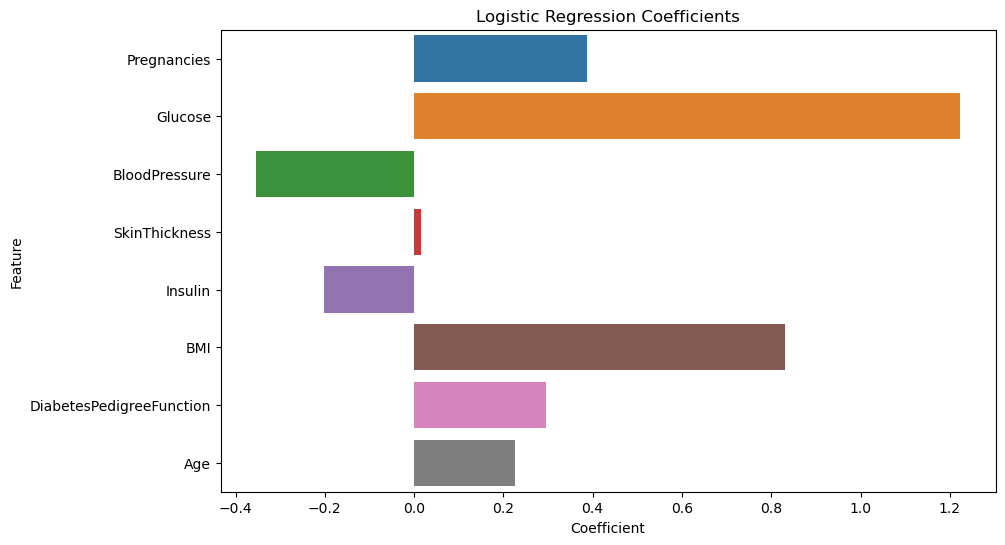

In [134]:
plt.figure(figsize=(10, 6))
sns.barplot(x='Coefficient', y='Feature', data=coef_df)
plt.title('Logistic Regression Coefficients')
plt.show()